# Formula 1 Podium Prediction Companion — Member 1

This notebook covers the Member 1 part of the project: loading the raw data, checking its quality, cleaning it, fixing the driver-race duplicates, and preparing a clean handoff for the next part.

The required grain is one row per driver per race. The raw CSV files are kept unchanged.

## 1. Project Setup

The notebook finds the project folder automatically so it can run without changing paths by hand. Output folders are created only for cleaned data, reports, and figures.

In [2]:
from pathlib import Path
import hashlib
import warnings
import numpy as np
import pandas as pd
import matplotlib

if "get_ipython" not in globals():
    matplotlib.use("Agg")
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)

def find_project_root(start: Path) -> Path:
    start = start.resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "data" / "raw").exists():
            return candidate
    raise FileNotFoundError("Could not find data/raw from current working directory.")

PROJECT_ROOT = find_project_root(Path.cwd())
RAW_DIR = PROJECT_ROOT / "data" / "raw"
CLEAN_DIR = PROJECT_ROOT / "data" / "cleaned"
CLEAN_TABLE_DIR = CLEAN_DIR / "tables"
REPORT_DIR = PROJECT_ROOT / "reports"
FIG_DIR = REPORT_DIR / "figures"
for d in [CLEAN_DIR, CLEAN_TABLE_DIR, REPORT_DIR, FIG_DIR]:
    d.mkdir(parents=True, exist_ok=True)

EXPECTED_TABLES = [
    "circuits", "constructors", "constructor_results", "constructor_standings",
    "drivers", "driver_standings", "races", "results", "qualifying",
    "lap_times", "pit_stops", "sprint_results", "seasons", "status"
]

PK_MAP = {
    "circuits": ["circuitId"],
    "constructors": ["constructorId"],
    "constructor_results": ["constructorResultsId"],
    "constructor_standings": ["constructorStandingsId"],
    "drivers": ["driverId"],
    "driver_standings": ["driverStandingsId"],
    "races": ["raceId"],
    "results": ["resultId"],
    "qualifying": ["qualifyId"],
    "lap_times": ["raceId", "driverId", "lap"],
    "pit_stops": ["raceId", "driverId", "stop"],
    "sprint_results": ["resultId"],
    "seasons": ["year"],
    "status": ["statusId"],
}

FK_RELATIONSHIPS = [
    ("races", "circuitId", "circuits", "circuitId"),
    ("races", "year", "seasons", "year"),
    ("results", "raceId", "races", "raceId"),
    ("results", "driverId", "drivers", "driverId"),
    ("results", "constructorId", "constructors", "constructorId"),
    ("results", "statusId", "status", "statusId"),
    ("qualifying", "raceId", "races", "raceId"),
    ("qualifying", "driverId", "drivers", "driverId"),
    ("qualifying", "constructorId", "constructors", "constructorId"),
    ("driver_standings", "raceId", "races", "raceId"),
    ("driver_standings", "driverId", "drivers", "driverId"),
    ("constructor_results", "raceId", "races", "raceId"),
    ("constructor_results", "constructorId", "constructors", "constructorId"),
    ("constructor_standings", "raceId", "races", "raceId"),
    ("constructor_standings", "constructorId", "constructors", "constructorId"),
    ("lap_times", "raceId", "races", "raceId"),
    ("lap_times", "driverId", "drivers", "driverId"),
    ("pit_stops", "raceId", "races", "raceId"),
    ("pit_stops", "driverId", "drivers", "driverId"),
    ("sprint_results", "raceId", "races", "raceId"),
    ("sprint_results", "driverId", "drivers", "driverId"),
    ("sprint_results", "constructorId", "constructors", "constructorId"),
    ("sprint_results", "statusId", "status", "statusId"),
]

def sha256_file(path: Path) -> str:
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def raw_hashes():
    return {p.name: sha256_file(p) for p in sorted(RAW_DIR.glob("*.csv"))}

def duration_to_seconds(value):
    if pd.isna(value):
        return np.nan
    s = str(value).strip()
    if not s:
        return np.nan
    if s.startswith("+"):
        s = s[1:]
    try:
        parts = [float(x) for x in s.split(":")]
    except ValueError:
        return np.nan
    if len(parts) == 1:
        return parts[0]
    if len(parts) == 2:
        return parts[0] * 60 + parts[1]
    if len(parts) == 3:
        return parts[0] * 3600 + parts[1] * 60 + parts[2]
    return np.nan

def audit_table(name, df):
    pk = PK_MAP.get(name, [])
    normalized_pk = df[pk].replace({r"\N": pd.NA, "": pd.NA}) if pk else pd.DataFrame(index=df.index)
    dup_mask = normalized_pk.duplicated(pk, keep=False) if pk else pd.Series(False, index=df.index)
    return {
        "table": name,
        "rows": len(df),
        "columns": len(df.columns),
        "sentinel_cells": int(df.eq(r"\N").sum().sum()),
        "empty_string_cells": int(df.eq("").sum().sum()),
        "exact_duplicate_rows": int(df.duplicated().sum()),
        "expected_pk": ", ".join(pk),
        "pk_null_rows": int(normalized_pk.isna().any(axis=1).sum()) if pk else 0,
        "pk_duplicate_rows": int(dup_mask.sum()) if pk else 0,
        "pk_duplicate_keys": int(normalized_pk.loc[dup_mask, pk].drop_duplicates().shape[0]) if pk else 0,
    }

def validate_primary_keys(tables):
    out = []
    for name, pk in PK_MAP.items():
        df = tables[name]
        null_rows = int(df[pk].isna().any(axis=1).sum())
        dup_mask = df.duplicated(pk, keep=False)
        out.append({
            "table": name,
            "primary_key": ", ".join(pk),
            "rows": len(df),
            "null_key_rows": null_rows,
            "duplicate_key_rows": int(dup_mask.sum()),
            "duplicate_key_values": int(df.loc[dup_mask, pk].drop_duplicates().shape[0]),
            "valid": null_rows == 0 and int(dup_mask.sum()) == 0,
        })
    return pd.DataFrame(out)

def validate_foreign_keys(tables):
    out = []
    for child, child_col, parent, parent_col in FK_RELATIONSHIPS:
        child_vals = tables[child][child_col].dropna()
        parent_vals = set(tables[parent][parent_col].dropna().tolist())
        unmatched = child_vals[~child_vals.isin(parent_vals)]
        out.append({
            "child": child,
            "foreign_key": child_col,
            "parent": parent,
            "parent_key": parent_col,
            "checked_rows": len(child_vals),
            "distinct_values": int(child_vals.nunique()),
            "unmatched_rows": int(len(unmatched)),
            "unmatched_distinct": int(unmatched.nunique()),
            "example_unmatched": ", ".join(map(str, unmatched.drop_duplicates().head(10).tolist())),
        })
    return pd.DataFrame(out)

RAW_HASH_BEFORE = raw_hashes()
print("PROJECT_ROOT", PROJECT_ROOT)
print("Raw CSV count", len(RAW_HASH_BEFORE))


PROJECT_ROOT /drive/notebooks/MS1
Raw CSV count 14


## 2. Imports

The setup uses pandas, NumPy, pathlib, hashing utilities, and matplotlib. No modeling libraries are needed in this part.

## 3. Data Loading

All 14 CSV files are loaded as strings first. This is done so values such as \N can be counted before they are converted to missing values.

In [3]:
csv_paths = {p.stem: p for p in sorted(RAW_DIR.glob("*.csv"))}
missing_tables = sorted(set(EXPECTED_TABLES) - set(csv_paths))
assert not missing_tables, f"Missing required tables: {missing_tables}"

raw_tables = {
    name: pd.read_csv(path, dtype=str, keep_default_na=False)
    for name, path in csv_paths.items()
}
print("Loaded", len(raw_tables), "tables")


Loaded 14 tables


## 4. Dataset Overview

A compact audit is produced for every table. It records table size, missing sentinels, exact duplicate rows, and the expected primary key. This gives a clear picture of the raw data before cleaning.

                table   rows  columns  sentinel_cells  empty_string_cells  exact_duplicate_rows            expected_pk  pk_null_rows  pk_duplicate_rows  pk_duplicate_keys
             circuits     77        9               0                   0                     0              circuitId             0                  0                  0
  constructor_results  12625        5           12608                   0                     0   constructorResultsId             0                  0                  0
constructor_standings  13391        7               0                   0                     0 constructorStandingsId             0                  0                  0
         constructors    212        5               0                   0                     0          constructorId             0                  0                  0
     driver_standings  34863        7               0                   0                     0      driverStandingsId             0             

<ipython-input-4-21bb7bf7f0d4>:16: MatplotlibDeprecationWarning: The width parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(width) instead.
  plt.tight_layout()
<ipython-input-4-21bb7bf7f0d4>:16: MatplotlibDeprecationWarning: The height parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(height) instead.
  plt.tight_layout()
<ipython-input-4-21bb7bf7f0d4>:16: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.tight_layout()
<ipython-input-4-21bb7bf7f0d4>:16: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.tight_layout()
<ipython-input-4-21bb7bf7f0d4>:17: MatplotlibDeprecationWarning: The width parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(width) instead.
  plt.savefig(FIG_DIR / "

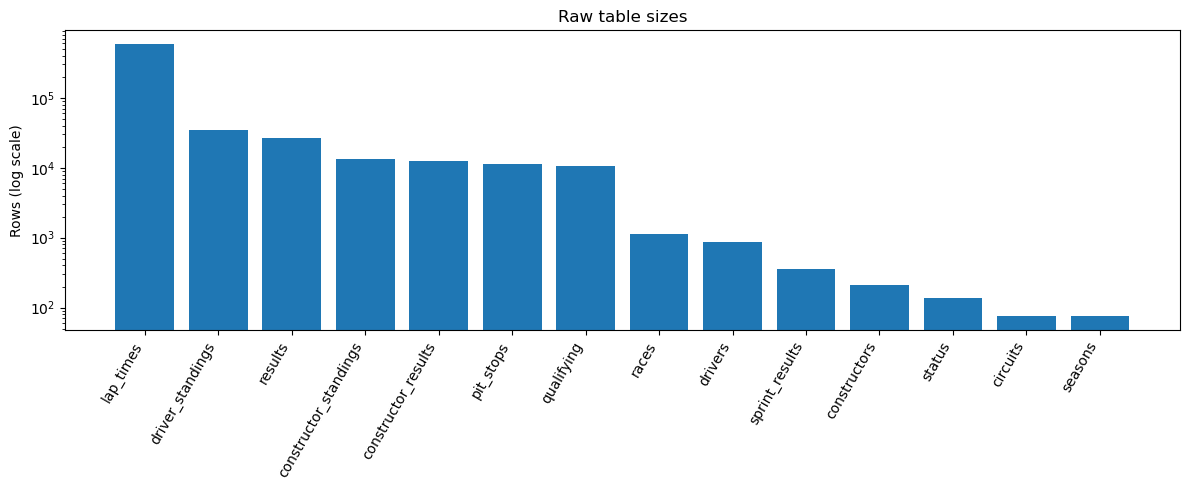

In [4]:
raw_audit = pd.DataFrame([audit_table(name, raw_tables[name]) for name in EXPECTED_TABLES])
raw_audit = raw_audit.sort_values("table").reset_index(drop=True)
raw_audit.to_csv(REPORT_DIR / "member1_raw_dataset_audit.csv", index=False)
print(raw_audit.to_string(index=False))
sentinel_before = int(raw_audit["sentinel_cells"].sum())
print("Total literal sentinel cells", sentinel_before)
print("Total exact duplicate rows", int(raw_audit["exact_duplicate_rows"].sum()))

plt.figure(figsize=(12, 5))
sizes = raw_audit.sort_values("rows", ascending=False)
plt.bar(sizes["table"], sizes["rows"])
plt.yscale("log")
plt.xticks(rotation=60, ha="right")
plt.ylabel("Rows (log scale)")
plt.title("Raw table sizes")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_raw_table_sizes.png", dpi=160)
plt.show()
plt.show()
plt.show()
plt.show()
plt.show()
plt.show()
plt.close()


## 5. Initial EDA

The first EDA checks table sizes, sentinel values, season coverage, grid and finishing-position distributions, and a few obvious range problems. The plots here are only used to show useful data-quality patterns.

In [5]:
sentinel_by_table = raw_audit[raw_audit["sentinel_cells"] > 0].sort_values("sentinel_cells", ascending=False)
plt.figure(figsize=(10, 5))
plt.bar(sentinel_by_table["table"], sentinel_by_table["sentinel_cells"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("Literal sentinel cells")
plt.title("Sentinel missing values before cleaning")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_raw_sentinel_by_table.png", dpi=160)
plt.close()
print("Initial EDA finding: sentinels occur in", sentinel_by_table["table"].tolist())

races_year = raw_tables["races"][["raceId", "year"]].copy()
races_year["year_num"] = pd.to_numeric(races_year["year"], errors="coerce")
results_year = raw_tables["results"][["raceId", "driverId", "grid", "positionOrder"]].merge(
    races_year[["raceId", "year_num"]], on="raceId", how="left", validate="many_to_one"
)
coverage = results_year.groupby("year_num").size()
plt.figure(figsize=(12, 4))
plt.plot(coverage.index, coverage.values)
plt.xlabel("Season")
plt.ylabel("Result rows")
plt.title("Driver-result coverage across seasons")
plt.tight_layout()
plt.savefig(FIG_DIR / "03_results_time_coverage.png", dpi=160)
plt.close()
print("Results coverage", int(coverage.index.min()), "to", int(coverage.index.max()))

grid_num = pd.to_numeric(raw_tables["results"]["grid"], errors="coerce")
finish_num = pd.to_numeric(raw_tables["results"]["positionOrder"], errors="coerce")
plt.figure(figsize=(10, 4))
plt.hist(grid_num.dropna(), bins=35, alpha=0.65, label="Grid")
plt.hist(finish_num.dropna(), bins=35, alpha=0.45, label="Position order")
plt.xlabel("Position")
plt.ylabel("Rows")
plt.title("Raw grid and finishing-order distributions")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "04_raw_grid_finish_distribution.png", dpi=160)
plt.close()
print("Grid zero rows preserved as meaningful historical cases:", int((grid_num == 0).sum()))

checks = []
circuits_raw = raw_tables["circuits"]
lat = pd.to_numeric(circuits_raw["lat"], errors="coerce")
lng = pd.to_numeric(circuits_raw["lng"], errors="coerce")
checks.append(("circuits latitude outside [-90,90]", int((lat.notna() & ~lat.between(-90, 90)).sum())))
checks.append(("circuits longitude outside [-180,180]", int((lng.notna() & ~lng.between(-180, 180)).sum())))
results_raw = raw_tables["results"]
checks.append(("results positionOrder < 1", int((pd.to_numeric(results_raw["positionOrder"], errors="coerce") < 1).sum())))
checks.append(("results laps < 0", int((pd.to_numeric(results_raw["laps"], errors="coerce") < 0).sum())))
checks.append(("results points < 0", int((pd.to_numeric(results_raw["points"], errors="coerce") < 0).sum())))
qual_raw = raw_tables["qualifying"]
checks.append(("qualifying position < 1", int((pd.to_numeric(qual_raw["position"], errors="coerce") < 1).sum())))
lap_raw = raw_tables["lap_times"]
checks.append(("lap_times lap < 1", int((pd.to_numeric(lap_raw["lap"], errors="coerce") < 1).sum())))
checks.append(("lap_times milliseconds <= 0", int((pd.to_numeric(lap_raw["milliseconds"], errors="coerce") <= 0).sum())))
pit_raw = raw_tables["pit_stops"]
checks.append(("pit_stops stop < 1", int((pd.to_numeric(pit_raw["stop"], errors="coerce") < 1).sum())))
checks.append(("pit_stops lap < 1", int((pd.to_numeric(pit_raw["lap"], errors="coerce") < 1).sum())))
range_check_df = pd.DataFrame(checks, columns=["check", "flagged_rows"])
range_check_df.to_csv(REPORT_DIR / "member1_obvious_value_checks.csv", index=False)
print(range_check_df.to_string(index=False))


<ipython-input-5-25e983bb3cab>:8: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig(FIG_DIR / "02_raw_sentinel_by_table.png", dpi=160)
<ipython-input-5-25e983bb3cab>:8: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig(FIG_DIR / "02_raw_sentinel_by_table.png", dpi=160)


Initial EDA finding: sentinels occur in ['results', 'constructor_results', 'qualifying', 'races', 'drivers', 'sprint_results']


<ipython-input-5-25e983bb3cab>:24: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig(FIG_DIR / "03_results_time_coverage.png", dpi=160)
<ipython-input-5-25e983bb3cab>:24: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig(FIG_DIR / "03_results_time_coverage.png", dpi=160)


Results coverage 1950 to 2024


<ipython-input-5-25e983bb3cab>:38: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig(FIG_DIR / "04_raw_grid_finish_distribution.png", dpi=160)
<ipython-input-5-25e983bb3cab>:38: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig(FIG_DIR / "04_raw_grid_finish_distribution.png", dpi=160)


Grid zero rows preserved as meaningful historical cases: 1638
                                check  flagged_rows
   circuits latitude outside [-90,90]             0
circuits longitude outside [-180,180]             0
            results positionOrder < 1             0
                     results laps < 0             0
                   results points < 0             0
              qualifying position < 1             0
                    lap_times lap < 1             0
          lap_times milliseconds <= 0             0
                   pit_stops stop < 1             0
                    pit_stops lap < 1             0


## 6. Missing Values and Sentinel Cleaning

The literal \N values are replaced with proper pandas missing values on copies of the data. The raw CSV files are not changed.

In [6]:
clean_tables = {name: df.copy(deep=True) for name, df in raw_tables.items()}
for name, df in clean_tables.items():
    clean_tables[name] = df.replace(r"\N", pd.NA)

INT_COLS = {
    "circuits": ["circuitId", "alt"],
    "constructor_results": ["constructorResultsId", "raceId", "constructorId"],
    "constructor_standings": ["constructorStandingsId", "raceId", "constructorId", "position", "wins"],
    "constructors": ["constructorId"],
    "driver_standings": ["driverStandingsId", "raceId", "driverId", "position", "wins"],
    "drivers": ["driverId", "number"],
    "lap_times": ["raceId", "driverId", "lap", "position", "milliseconds"],
    "pit_stops": ["raceId", "driverId", "stop", "lap", "milliseconds"],
    "qualifying": ["qualifyId", "raceId", "driverId", "constructorId", "number", "position"],
    "races": ["raceId", "year", "round", "circuitId"],
    "results": ["resultId", "raceId", "driverId", "constructorId", "number", "grid", "position", "positionOrder", "laps", "milliseconds", "fastestLap", "rank", "statusId"],
    "seasons": ["year"],
    "sprint_results": ["resultId", "raceId", "driverId", "constructorId", "number", "grid", "position", "positionOrder", "laps", "milliseconds", "fastestLap", "statusId"],
    "status": ["statusId"],
}
FLOAT_COLS = {
    "circuits": ["lat", "lng"],
    "constructor_results": ["points"],
    "constructor_standings": ["points"],
    "driver_standings": ["points"],
    "results": ["points", "fastestLapSpeed"],
    "sprint_results": ["points"],
}
DATE_COLS = {
    "drivers": ["dob"],
    "races": ["date", "fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date"],
}

conversion_log = []
for table, cols in INT_COLS.items():
    for col in cols:
        clean_tables[table][col] = pd.to_numeric(clean_tables[table][col], errors="coerce").astype("Int64")
        conversion_log.append((table, col, "Int64"))

for table, cols in FLOAT_COLS.items():
    for col in cols:
        clean_tables[table][col] = pd.to_numeric(clean_tables[table][col], errors="coerce").astype("Float64")
        conversion_log.append((table, col, "Float64"))

for table, cols in DATE_COLS.items():
    for col in cols:
        clean_tables[table][col] = pd.to_datetime(clean_tables[table][col], errors="coerce")
        conversion_log.append((table, col, "datetime64[ns]"))

for col in ["q1", "q2", "q3"]:
    clean_tables["qualifying"][col + "_seconds"] = clean_tables["qualifying"][col].map(duration_to_seconds).astype("Float64")
    conversion_log.append(("qualifying", col + "_seconds", "Float64 seconds"))
clean_tables["lap_times"]["lap_time_seconds"] = clean_tables["lap_times"]["time"].map(duration_to_seconds).astype("Float64")
conversion_log.append(("lap_times", "lap_time_seconds", "Float64 seconds"))
clean_tables["pit_stops"]["duration_seconds"] = clean_tables["pit_stops"]["duration"].map(duration_to_seconds).astype("Float64")
conversion_log.append(("pit_stops", "duration_seconds", "Float64 seconds"))
clean_tables["results"]["fastestLapTime_seconds"] = clean_tables["results"]["fastestLapTime"].map(duration_to_seconds).astype("Float64")
conversion_log.append(("results", "fastestLapTime_seconds", "Float64 seconds"))
clean_tables["sprint_results"]["fastestLapTime_seconds"] = clean_tables["sprint_results"]["fastestLapTime"].map(duration_to_seconds).astype("Float64")
conversion_log.append(("sprint_results", "fastestLapTime_seconds", "Float64 seconds"))

for table, df in clean_tables.items():
    for col in df.columns:
        if df[col].dtype == object:
            df[col] = df[col].astype("string")

conversion_df = pd.DataFrame(conversion_log, columns=["table", "column", "semantic_type"])
conversion_df.to_csv(REPORT_DIR / "member1_type_conversions.csv", index=False)

remaining_sentinels = sum(int(df.astype("string").eq(r"\N").sum().sum()) for df in clean_tables.values())
assert remaining_sentinels == 0
print("Remaining literal sentinel cells", remaining_sentinels)


Remaining literal sentinel cells 0


## 7. Data Type Audit

IDs and numeric fields are converted to numeric types, dates are converted to datetime values, and useful duration fields are also converted to seconds. The original duration text is kept as well.

In [7]:
dtype_rows = []
for name in EXPECTED_TABLES:
    raw_df = raw_tables[name]
    clean_df = clean_tables[name]
    for col in clean_df.columns:
        raw_dtype = str(raw_df[col].dtype) if col in raw_df.columns else "(new)"
        clean_dtype = str(clean_df[col].dtype)
        if raw_dtype != clean_dtype or col not in raw_df.columns:
            dtype_rows.append({"table": name, "column": col, "raw_dtype": raw_dtype, "clean_dtype": clean_dtype})
dtype_change_df = pd.DataFrame(dtype_rows)
dtype_change_df.to_csv(REPORT_DIR / "member1_dtype_changes.csv", index=False)
print("Documented semantic conversions", len(dtype_change_df))


Documented semantic conversions 87


## 8. Primary Key Validation

The expected primary key of each table is checked for missing values and duplicates. The notebook stops if a required key is not valid.

In [8]:
pk_validation = validate_primary_keys(clean_tables)
pk_validation.to_csv(REPORT_DIR / "member1_pk_validation.csv", index=False)
print(pk_validation.to_string(index=False))
assert pk_validation["valid"].all()
print("PK validation PASS")


                table            primary_key   rows  null_key_rows  duplicate_key_rows  duplicate_key_values  valid
             circuits              circuitId     77              0                   0                     0   True
         constructors          constructorId    212              0                   0                     0   True
  constructor_results   constructorResultsId  12625              0                   0                     0   True
constructor_standings constructorStandingsId  13391              0                   0                     0   True
              drivers               driverId    861              0                   0                     0   True
     driver_standings      driverStandingsId  34863              0                   0                     0   True
                races                 raceId   1125              0                   0                     0   True
              results               resultId  26759              0      

## 9. Foreign Key Validation

Important relationships between the tables are checked, including race, driver, constructor, circuit, and status IDs. Any unmatched values would be listed in the validation output.

In [9]:
fk_validation = validate_foreign_keys(clean_tables)
fk_validation.to_csv(REPORT_DIR / "member1_fk_validation.csv", index=False)
print(fk_validation.to_string(index=False))
assert int(fk_validation["unmatched_rows"].sum()) == 0
print("FK validation PASS")


                child   foreign_key       parent    parent_key  checked_rows  distinct_values  unmatched_rows  unmatched_distinct example_unmatched
                races     circuitId     circuits     circuitId          1125               77               0                   0                  
                races          year      seasons          year          1125               75               0                   0                  
              results        raceId        races        raceId         26759             1125               0                   0                  
              results      driverId      drivers      driverId         26759              861               0                   0                  
              results constructorId constructors constructorId         26759              211               0                   0                  
              results      statusId       status      statusId         26759              137               0   

## 10. Cleaning Decisions

The cleaning is kept conservative. Missing sentinels are normalized and data types are fixed, but rows are not removed just because ordinary values are missing. Grid value 0 is also kept because it can be meaningful in historical races.

## 11. Driver-Race Duplicate Investigation

The project requires one row for each raceId and driverId pair. The raw results contain historical shared-drive cases where the same driver appears more than once in one race, so those rows are examined before anything is removed.

In [10]:
results_clean = clean_tables["results"].copy()
dup_mask = results_clean.duplicated(["raceId", "driverId"], keep=False)
dup_rows = results_clean.loc[dup_mask].copy()
dup_pair_count = int(dup_rows[["raceId", "driverId"]].drop_duplicates().shape[0])

race_labels = clean_tables["races"][["raceId", "year", "name"]].rename(columns={"name": "race_name"})
dup_detail = dup_rows.merge(race_labels, on="raceId", how="left", validate="many_to_one")
dup_detail = dup_detail.sort_values(["year", "raceId", "driverId", "positionOrder", "resultId"])
pair_stats = (
    dup_detail.groupby(["raceId", "driverId"], as_index=False)
    .agg(
        year=("year", "first"),
        race_name=("race_name", "first"),
        records=("resultId", "size"),
        distinct_grids=("grid", "nunique"),
        distinct_constructors=("constructorId", "nunique"),
        best_positionOrder=("positionOrder", "min"),
        worst_positionOrder=("positionOrder", "max"),
    )
)
pair_stats["mixed_podium_outcome"] = pair_stats["best_positionOrder"].le(3) & pair_stats["worst_positionOrder"].gt(3)
dup_detail.to_csv(REPORT_DIR / "member1_driver_race_duplicate_details_before.csv", index=False)
pair_stats.to_csv(REPORT_DIR / "member1_driver_race_duplicate_pair_summary.csv", index=False)

print("Duplicate pairs", dup_pair_count)
print("Duplicate rows", len(dup_rows))
print("Affected years", int(dup_detail["year"].min()), "to", int(dup_detail["year"].max()))
print("Pairs with different grids", int((pair_stats["distinct_grids"] > 1).sum()))
print("Pairs with different constructors", int((pair_stats["distinct_constructors"] > 1).sum()))
print("Pairs mixing podium and non-podium rows", int(pair_stats["mixed_podium_outcome"].sum()))


Duplicate pairs 85
Duplicate rows 176
Affected years 1950 to 1978
Pairs with different grids 81
Pairs with different constructors 16
Pairs mixing podium and non-podium rows 21


## 12. Duplicate Resolution

For a duplicated driver-race pair, the row with the best official positionOrder is kept. If there is a tie, the row with more completed laps is kept, then the smaller resultId is used as the final tie-breaker.

This rule fits the podium target because it keeps the driver's best official classification for that race. The removed rows are saved in a report so the decision can still be checked.

In [11]:
working = results_clean.copy()
working["_pos_sort"] = working["positionOrder"].astype("Float64").fillna(np.inf)
working["_laps_sort"] = working["laps"].astype("Float64").fillna(-np.inf)
working["_result_sort"] = working["resultId"].astype("Float64").fillna(np.inf)
ranked = working.sort_values(
    ["raceId", "driverId", "_pos_sort", "_laps_sort", "_result_sort"],
    ascending=[True, True, True, False, True],
)
kept = ranked.drop_duplicates(["raceId", "driverId"], keep="first").copy()
kept_ids = kept[["raceId", "driverId", "resultId"]].rename(columns={"resultId": "kept_resultId"})
removed = ranked[ranked.duplicated(["raceId", "driverId"], keep="first")].copy()
removed = removed.merge(kept_ids, on=["raceId", "driverId"], how="left", validate="many_to_one")
removed["resolution_rule"] = "best positionOrder; tie: more laps; tie: smaller resultId"
helper_cols = ["_pos_sort", "_laps_sort", "_result_sort"]
results_driver_race = kept.drop(columns=helper_cols).sort_values(["raceId", "driverId"]).reset_index(drop=True)
removed_log = removed.drop(columns=helper_cols).sort_values(["raceId", "driverId", "resultId"]).reset_index(drop=True)
removed_log.to_csv(REPORT_DIR / "member1_duplicate_resolution_log.csv", index=False)

assert results_driver_race.duplicated(["raceId", "driverId"]).sum() == 0
assert len(results_clean) - len(results_driver_race) == len(removed_log)
print("Rows before", len(results_clean))
print("Rows after", len(results_driver_race))
print("Rows removed", len(removed_log))


Rows before 26759
Rows after 26668
Rows removed 91


## 13. Post-Cleaning EDA

The main checks are repeated after cleaning so the effect can be seen directly: sentinel counts, row counts, missingness, and driver-race duplicates.

In [12]:
sentinel_after = sum(int(df.astype("string").eq(r"\N").sum().sum()) for df in clean_tables.values())
duplicate_pairs_after = int(results_driver_race.duplicated(["raceId", "driverId"]).sum())
comparison = pd.DataFrame({
    "metric": ["literal sentinel cells", "results rows", "duplicated driver-race pairs"],
    "before": [sentinel_before, len(raw_tables["results"]), dup_pair_count],
    "after": [sentinel_after, len(results_driver_race), duplicate_pairs_after],
})
comparison.to_csv(REPORT_DIR / "member1_before_after_summary.csv", index=False)
print(comparison.to_string(index=False))

plt.figure(figsize=(7, 4))
x = np.arange(2)
before = [sentinel_before, dup_pair_count]
after = [sentinel_after, duplicate_pairs_after]
width = 0.35
plt.bar(x - width / 2, before, width, label="Before")
plt.bar(x + width / 2, after, width, label="After")
plt.xticks(x, ["Sentinel cells", "Duplicate driver-race pairs"])
plt.yscale("symlog", linthresh=1)
plt.ylabel("Count")
plt.title("Cleaning impact")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "05_cleaning_impact.png", dpi=160)
plt.close()

missing_rows = []
for name, df in clean_tables.items():
    for col in df.columns:
        n = int(df[col].isna().sum())
        if n:
            missing_rows.append({
                "table": name,
                "column": col,
                "missing_rows": n,
                "missing_pct": 100 * n / len(df),
            })
missing_after = pd.DataFrame(missing_rows).sort_values("missing_pct", ascending=False)
missing_after.to_csv(REPORT_DIR / "member1_missingness_after_cleaning.csv", index=False)

top_missing = missing_after.head(15).copy()
plt.figure(figsize=(11, 5))
labels = top_missing["table"] + "." + top_missing["column"]
plt.bar(labels, top_missing["missing_pct"])
plt.xticks(rotation=65, ha="right")
plt.ylabel("Missing rows (%)")
plt.title("Highest remaining missingness after cleaning")
plt.tight_layout()
plt.savefig(FIG_DIR / "06_post_cleaning_missingness.png", dpi=160)
plt.close()


                      metric  before  after
      literal sentinel cells  160076      0
                results rows   26759  26668
duplicated driver-race pairs      85      0


<ipython-input-12-0935e85c105c>:23: MatplotlibDeprecationWarning: The width parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(width) instead.
  plt.tight_layout()
<ipython-input-12-0935e85c105c>:23: MatplotlibDeprecationWarning: The height parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(height) instead.
  plt.tight_layout()
<ipython-input-12-0935e85c105c>:23: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.tight_layout()
<ipython-input-12-0935e85c105c>:23: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.tight_layout()
<ipython-input-12-0935e85c105c>:24: MatplotlibDeprecationWarning: The width parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(width) instead.
  plt.savefig(FIG_DI

## 14. Final Validation

The final checks confirm that the driver-race grain is unique, the required IDs are valid, the source-table keys still pass validation, and the raw CSV files have not changed.

In [13]:
for col in ["raceId", "driverId", "constructorId", "statusId"]:
    assert results_driver_race[col].notna().all()
assert results_driver_race["positionOrder"].notna().all()
assert results_driver_race.duplicated(["raceId", "driverId"]).sum() == 0
assert results_driver_race["raceId"].isin(clean_tables["races"]["raceId"]).all()
assert results_driver_race["driverId"].isin(clean_tables["drivers"]["driverId"]).all()
assert results_driver_race["constructorId"].isin(clean_tables["constructors"]["constructorId"]).all()
assert results_driver_race["statusId"].isin(clean_tables["status"]["statusId"]).all()
assert validate_primary_keys(clean_tables)["valid"].all()

RAW_HASH_AFTER = raw_hashes()
assert RAW_HASH_BEFORE == RAW_HASH_AFTER
pd.DataFrame([{"file": k, "sha256": v} for k, v in RAW_HASH_AFTER.items()]).to_csv(
    REPORT_DIR / "member1_raw_file_sha256.csv", index=False
)
print("Final validation PASS")


Final validation PASS


## 15. Export and Handoff

The main handoff file is driver_race_handoff.csv. It contains one row per driver per race and is the starting point for the next member.

A second file, driver_race_base_full_audit.csv, is kept only for auditing because it contains post-race fields and should not be used directly as model features. Cleaned copies of the 14 source tables are also exported.

In [14]:
for name, df in clean_tables.items():
    df.to_csv(CLEAN_TABLE_DIR / (name + "_clean.csv"), index=False)

results_driver_race.to_csv(CLEAN_DIR / "results_driver_race_clean.csv", index=False)

race_meta = clean_tables["races"][["raceId", "year", "round", "circuitId", "date"]].rename(
    columns={"year": "race_year", "round": "race_round", "date": "race_date"}
)
full_base = results_driver_race.merge(race_meta, on="raceId", how="left", validate="many_to_one")
full_base["podium"] = full_base["positionOrder"].le(3).astype("Int64")
full_base.to_csv(CLEAN_DIR / "driver_race_base_full_audit.csv", index=False)

handoff_cols = [
    "raceId", "driverId", "constructorId", "number", "grid",
    "race_year", "race_round", "circuitId", "race_date", "podium"
]
driver_race_handoff = full_base[handoff_cols].copy()
driver_race_handoff.to_csv(CLEAN_DIR / "driver_race_handoff.csv", index=False)

assert driver_race_handoff.duplicated(["raceId", "driverId"]).sum() == 0
assert len(driver_race_handoff) == len(results_driver_race)
assert driver_race_handoff[["raceId", "driverId", "constructorId", "circuitId"]].notna().all().all()


## 16. Member 1 Summary

The last cell prints the main cleaning results, the final row count, the output paths, and the main historical limitations.

In [15]:
summary_metrics = pd.DataFrame([
    ["tables_inspected", len(EXPECTED_TABLES)],
    ["raw_results_rows", len(raw_tables["results"])],
    ["raw_literal_sentinel_cells", sentinel_before],
    ["remaining_literal_sentinel_cells", sentinel_after],
    ["pk_violations", int((~pk_validation["valid"]).sum())],
    ["fk_unmatched_rows", int(fk_validation["unmatched_rows"].sum())],
    ["duplicate_driver_race_pairs_before", dup_pair_count],
    ["duplicate_driver_race_rows_before", len(dup_rows)],
    ["duplicate_rows_removed", len(removed_log)],
    ["duplicate_driver_race_pairs_after", duplicate_pairs_after],
    ["final_driver_race_rows", len(driver_race_handoff)],
    ["race_year_min", int(driver_race_handoff["race_year"].min())],
    ["race_year_max", int(driver_race_handoff["race_year"].max())],
], columns=["metric", "value"])
summary_metrics.to_csv(REPORT_DIR / "member1_cleaning_summary.csv", index=False)
print(summary_metrics.to_string(index=False))

print("Member 2 handoff:", CLEAN_DIR / "driver_race_handoff.csv")
print("Full audit base:", CLEAN_DIR / "driver_race_base_full_audit.csv")
print("Known limitation: early shared-drive rows are historically ambiguous; the retained grid and constructor belong to the row with the best official classification.")
print("Known limitation: qualifying coverage and session completeness vary by era.")
print("Leakage warning: full audit base contains post-race fields and must not be used directly as model features.")


                            metric  value
                  tables_inspected     14
                  raw_results_rows  26759
        raw_literal_sentinel_cells 160076
  remaining_literal_sentinel_cells      0
                     pk_violations      0
                 fk_unmatched_rows      0
duplicate_driver_race_pairs_before     85
 duplicate_driver_race_rows_before    176
            duplicate_rows_removed     91
 duplicate_driver_race_pairs_after      0
            final_driver_race_rows  26668
                     race_year_min   1950
                     race_year_max   2024
Member 2 handoff: /drive/notebooks/MS1/data/cleaned/driver_race_handoff.csv
Full audit base: /drive/notebooks/MS1/data/cleaned/driver_race_base_full_audit.csv
Known limitation: early shared-drive rows are historically ambiguous; the retained grid and constructor belong to the row with the best official classification.
Known limitation: qualifying coverage and session completeness vary by era.
Leakage warning: